# 09 · Análisis exploratorio

**Propósito:** responder con datos limpios las preguntas que se haría el jefe de turno del Centro de Control de
Operaciones (CCO) de LATAM en Brasil. Cada gráfico tiene una pregunta como título y debajo la respuesta con su cifra.
LATAM Brasil es el foco; EE. UU. sirve de contraste y para justificar que un solo modelo aprenda de los dos mercados.

**Entrada:** `silver/vuelos` y `gold/features_salida`. Nunca se lee `scale-test/` (réplicas para la prueba de
escalabilidad, que no son datos reales).

**Salida:** gráficos PNG y `hallazgos_eda.csv` (pregunta, hallazgo con cifra, implicancia) en `docs/evidencias/eda/`.

**Requisito:** notebooks 05 y 08.

In [1]:
import os
from pathlib import Path

import yaml

# Carpeta del repositorio (este notebook está en notebooks/)
RAIZ = Path.cwd().parent
with open(RAIZ / "config" / "pipeline.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
tablas = cfg["lake"]["tablas"]

# En la EC2 la variable LAKE_BUCKET trae el nombre del bucket; en una laptop se trabaja sobre data/lake
BUCKET = os.environ.get("LAKE_BUCKET", "").strip()
RAIZ_LOCAL = RAIZ / cfg["lake"]["raiz_local"]
BASE = f"s3a://{BUCKET}" if BUCKET else RAIZ_LOCAL.resolve().as_uri()


def ruta(tabla: str) -> str:
    """Ruta completa de una tabla declarada en config/pipeline.yaml."""
    return f"{BASE}/{tablas[tabla]}"


def meses(desde: str, hasta: str) -> list[tuple[int, int]]:
    """Pares (año, mes) entre dos fechas AAAA-MM, ambas incluidas."""
    anio, mes = map(int, desde.split("-"))
    anio_fin, mes_fin = map(int, hasta.split("-"))
    salida = []
    while (anio, mes) <= (anio_fin, mes_fin):
        salida.append((anio, mes))
        anio, mes = (anio + 1, 1) if mes == 12 else (anio, mes + 1)
    return salida


DESDE, HASTA = cfg["periodo"]["inicio"], cfg["periodo"]["fin"]
print("Destino:", f"s3://{BUCKET}" if BUCKET else "data/lake (local)")
print("Periodo:", DESDE, "a", HASTA)

Destino: s3://latam-bigdata-lake-728fd64c
Periodo: 2023-01 a 2025-12


In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark.sql.window import Window
import pandas as pd

# En la EC2 Spark toma la configuración del clúster (spark-defaults.conf); en una laptop corre en modo local
constructor = SparkSession.builder.appName("latam-bigdata-eda")
if not BUCKET:
    constructor = (
        constructor.master("local[*]")
        .config("spark.sql.shuffle.partitions", str(cfg["spark"]["particiones_shuffle_local"]))
        .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "3g"))
    )
spark = (
    constructor.config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.sources.partitionOverwriteMode", "dynamic")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")


def en_periodo(df, col_anio="year", col_mes="month"):
    """Deja solo las filas cuyo año y mes están dentro del periodo de config/pipeline.yaml."""
    ym = F.format_string("%04d-%02d", F.col(col_anio), F.col(col_mes))
    return df.where((ym >= DESDE) & (ym <= HASTA))

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/25 08:22:58 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/25 08:22:58 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


26/11/25 08:23:00 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


26/11/25 08:23:03 WARN S3ABlockOutputStream: Application invoked the Syncable API against stream writing to logs/spark-events/app-20261125082259-0006.inprogress. This is unsupported


In [3]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Paleta: una serie principal en azul; segunda y tercera en naranja y aqua; lo que no se destaca, en gris
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2"
TINTA, TINTA2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e7e6e1", "#fcfcfb"
matplotlib.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})

In [4]:
EVID = RAIZ / "docs" / "evidencias" / "eda"
EVID.mkdir(parents=True, exist_ok=True)
assert "scale-test" not in ruta("silver_vuelos") and "scale-test" not in ruta("gold_features")

LATAM = list(cfg["latam"]["pasajeros"])
COMPETIDORES = cfg["competidores"]
ANIO_BASE = int(HASTA[:4])
FUENTE = "Fuente: ANAC VRA, BTS On-Time Performance y METAR de Iowa Environmental Mesonet. Elaboración propia."

vuelos = en_periodo(spark.read.parquet(ruta("silver_vuelos")))
operados = vuelos.where(~F.col("cancelado") & ~F.col("desviado") & ~F.col("es_atipico") & F.col("y_demora15").isNotNull())
gold = spark.read.parquet(ruta("gold_features"))
segmento = F.when(F.col("es_latam"), "LATAM Brasil").when(F.col("pais") == "US", "EE. UU.").otherwise("Otras Brasil")
gold = gold.withColumn("segmento", segmento).cache()
hallazgos = []


def pct(x):
    return "s/d" if x is None or pd.isna(x) else f"{100 * x:.1f} %".replace(".", ",")


def miles(x):
    return f"{int(x):,}".replace(",", ".")


def lienzo(ancho=9.5, alto=5.2, izquierda=0.08):
    fig, ax = plt.subplots(figsize=(ancho, alto))
    fig.subplots_adjust(top=0.78, bottom=0.16, left=izquierda, right=0.97)
    return fig, ax


def cerrar(fig, nombre, pregunta, conclusion, implicancia):
    """Título = pregunta; subtítulo = respuesta con cifra; guarda el PNG y registra el hallazgo."""
    fig.text(0.02, 0.95, pregunta, fontsize=13, fontweight="bold", color=TINTA, va="top")
    fig.text(0.02, 0.885, conclusion, fontsize=10, color=TINTA2, va="top", linespacing=1.4)
    fig.text(0.02, 0.02, FUENTE, fontsize=7.5, color=TINTA2)
    fig.savefig(EVID / f"{nombre}.png", dpi=160)
    plt.show()
    hallazgos.append({"figura": f"{nombre}.png", "pregunta": pregunta,
                      "hallazgo": conclusion.replace("\n", " "), "implicancia": implicancia})


def tasa_por(df, *claves):
    return (df.groupBy(*claves).agg(F.avg("y_demora15").alias("t15"), F.avg("y_demora60").alias("t60"),
                                     F.count("*").alias("n")).toPandas())

## G1. ¿Cuál es la línea base de LATAM en Brasil y cómo evoluciona?

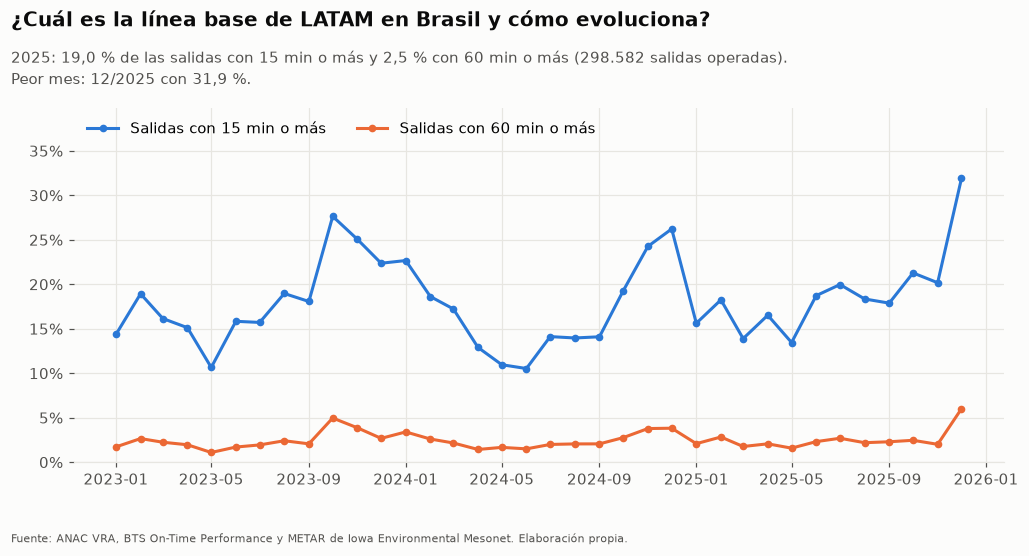

In [5]:
g1 = tasa_por(operados.where(F.col("es_latam")), "year", "month").sort_values(["year", "month"])
g1["fecha"] = pd.to_datetime(dict(year=g1.year, month=g1.month, day=1))
anual = (operados.where(F.col("es_latam")).groupBy("year")
         .agg(F.avg("y_demora15").alias("t15"), F.avg("y_demora60").alias("t60"), F.count("*").alias("n"))
         .toPandas().set_index("year"))
base = anual.loc[ANIO_BASE] if ANIO_BASE in anual.index else anual.iloc[-1]
anio = ANIO_BASE if ANIO_BASE in anual.index else int(anual.index[-1])

fig, ax = lienzo()
ax.plot(g1.fecha, g1.t15, color=AZUL, lw=2, marker="o", ms=4, label="Salidas con 15 min o más")
ax.plot(g1.fecha, g1.t60, color=NARANJA, lw=2, marker="o", ms=4, label="Salidas con 60 min o más")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, max(g1.t15.max() * 1.25, 0.05))
ax.legend(loc="upper left", ncol=2)
peor = g1.loc[g1.t15.idxmax()]
cerrar(fig, "g1_linea_base_latam",
       "¿Cuál es la línea base de LATAM en Brasil y cómo evoluciona?",
       f"{anio}: {pct(base.t15)} de las salidas con 15 min o más y {pct(base.t60)} con 60 min o más "
       f"({miles(base.n)} salidas operadas).\nPeor mes: {peor.fecha:%m/%Y} con {pct(peor.t15)}.",
       "Es la línea base contra la que se medirá el efecto de la alerta temprana.")

## G2. ¿LATAM sale más o menos puntual que Azul y Gol?

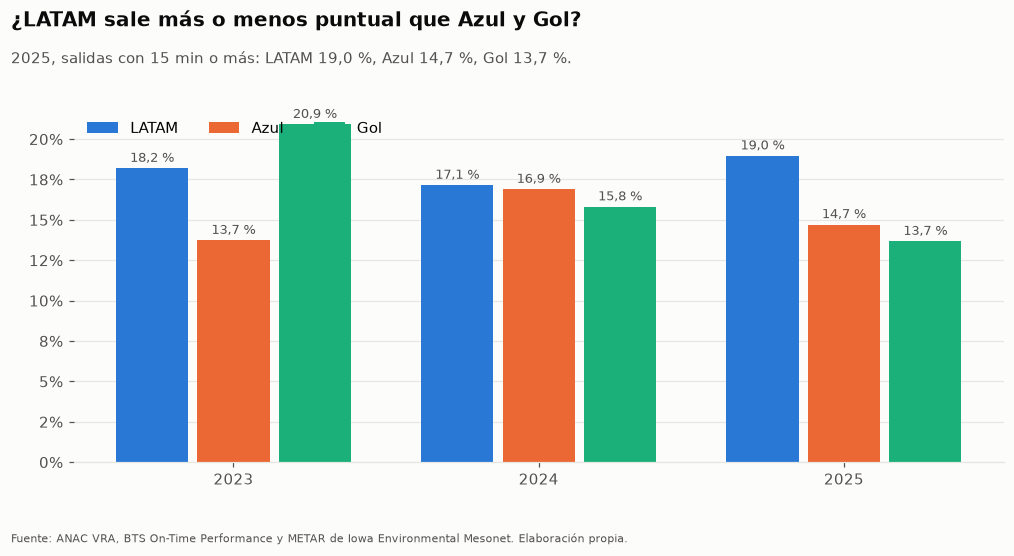

In [6]:
grupo = (F.when(F.col("es_latam"), "LATAM")
         .when(F.col("aerolinea") == "AZU", COMPETIDORES.get("AZU", "Azul"))
         .when(F.col("aerolinea") == "GLO", COMPETIDORES.get("GLO", "Gol")))
g2 = tasa_por(operados.where(F.col("pais") == "BR").withColumn("grupo", grupo).where(F.col("grupo").isNotNull()),
              "year", "grupo")
tabla = g2.pivot(index="year", columns="grupo", values="t15")
series = [(c, color) for c, color in zip(["LATAM", "Azul", "Gol"], [AZUL, NARANJA, AQUA]) if c in tabla.columns]
fig, ax = lienzo()
ancho = 0.8 / max(len(series), 1)
for i, (nombre, color) in enumerate(series):
    xs = [k + (i - (len(series) - 1) / 2) * ancho for k in range(len(tabla))]
    ax.bar(xs, tabla[nombre], width=ancho - 0.03, color=color, label=nombre)
    for x, v in zip(xs, tabla[nombre]):
        ax.text(x, v + 0.004, pct(v), ha="center", fontsize=8.5, color=TINTA2)
ax.set_xticks(range(len(tabla)), [str(a) for a in tabla.index])
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=3)
ultimo = tabla.iloc[-1]
cerrar(fig, "g2_latam_vs_competencia",
       "¿LATAM sale más o menos puntual que Azul y Gol?",
       f"{tabla.index[-1]}, salidas con 15 min o más: " + ", ".join(f"{c} {pct(ultimo.get(c))}" for c, _ in series) + ".",
       "Ubica a LATAM frente a su competencia directa en el mismo mercado y con la misma fuente.")

## G3. ¿Qué aeropuertos concentran las salidas demoradas de LATAM?

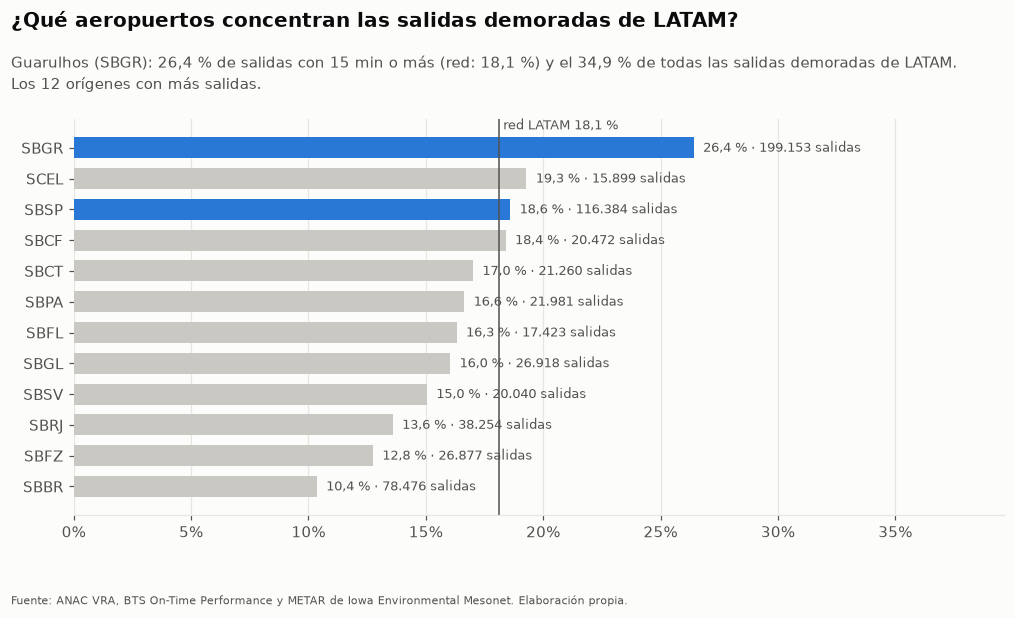

In [7]:
latam_op = operados.where(F.col("es_latam"))
g3 = (latam_op.groupBy("origen").agg(F.count("*").alias("n"), F.avg("y_demora15").alias("t15"),
                                     F.sum("y_demora15").alias("demoradas"))
      .orderBy(F.desc("n")).limit(12).toPandas().sort_values("t15"))
total_demoradas = latam_op.agg(F.sum("y_demora15")).first()[0] or 0
media = latam_op.agg(F.avg("y_demora15")).first()[0]
fig, ax = lienzo(9.5, 5.8)
ax.barh(g3.origen, g3.t15, color=[AZUL if o in ("SBGR", "SBSP") else GRIS for o in g3.origen], height=0.68)
for y, (t, n) in enumerate(zip(g3.t15, g3.n)):
    ax.text(t + 0.004, y, f"{pct(t)} · {miles(n)} salidas", va="center", fontsize=8.5, color=TINTA2)
ax.axvline(media, color=TINTA2, lw=1)
ax.text(media, len(g3) - 0.4, f" red LATAM {pct(media)}", fontsize=8.5, color=TINTA2)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, g3.t15.max() * 1.5)
ax.grid(axis="y", visible=False)
hub = g3.set_index("origen").reindex(["SBGR"]).iloc[0]
cuota = (hub.demoradas / total_demoradas) if total_demoradas and not pd.isna(hub.demoradas) else None
cerrar(fig, "g3_aeropuertos",
       "¿Qué aeropuertos concentran las salidas demoradas de LATAM?",
       f"Guarulhos (SBGR): {pct(hub.t15)} de salidas con 15 min o más (red: {pct(media)}) y el {pct(cuota)} de "
       "todas las salidas demoradas de LATAM.\nLos 12 orígenes con más salidas.",
       "Priorizar el turno del CCO en los hubs con más volumen y más demora.")

## G4. ¿En qué hora del día se concentra el riesgo?

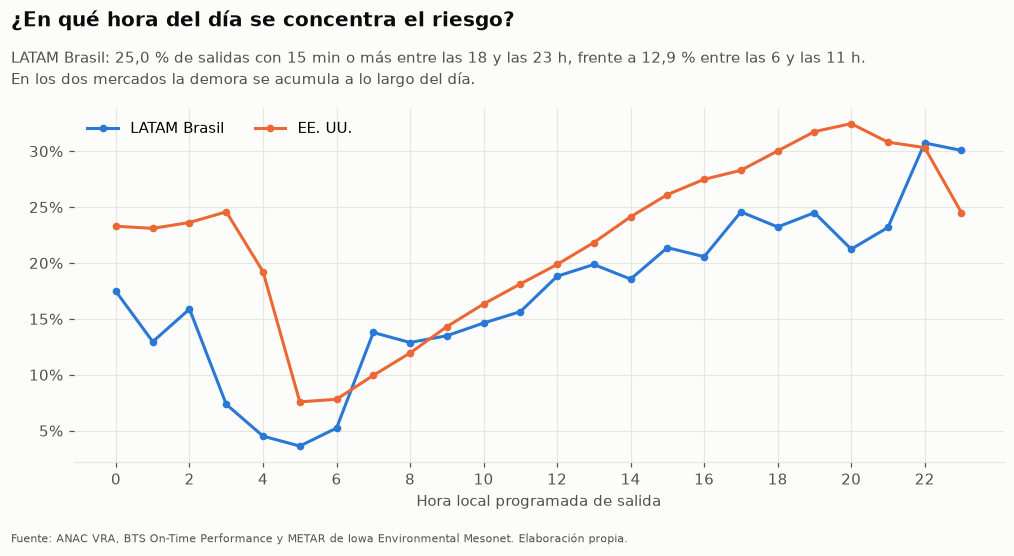

In [8]:
g4 = tasa_por(gold.where(F.col("segmento") != "Otras Brasil"), "segmento", "hora_local")
fig, ax = lienzo()
for nombre, color in [("LATAM Brasil", AZUL), ("EE. UU.", NARANJA)]:
    d = g4[g4.segmento == nombre].sort_values("hora_local")
    ax.plot(d.hora_local, d.t15, color=color, lw=2, marker="o", ms=4, label=nombre)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hora local programada de salida")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend(loc="upper left", ncol=2)
lat = g4[g4.segmento == "LATAM Brasil"]
noche = (lat[lat.hora_local >= 18].t15 * lat[lat.hora_local >= 18].n).sum() / max(lat[lat.hora_local >= 18].n.sum(), 1)
manana = (lat[lat.hora_local.between(6, 11)].t15 * lat[lat.hora_local.between(6, 11)].n).sum() / max(
    lat[lat.hora_local.between(6, 11)].n.sum(), 1)
cerrar(fig, "g4_hora_del_dia",
       "¿En qué hora del día se concentra el riesgo?",
       f"LATAM Brasil: {pct(noche)} de salidas con 15 min o más entre las 18 y las 23 h, frente a {pct(manana)} "
       "entre las 6 y las 11 h.\nEn los dos mercados la demora se acumula a lo largo del día.",
       "Reforzar la holgura y la vigilancia del CCO en el turno de tarde y noche.")

## G5. ¿El clima reportado a T−2 h anticipa la demora?

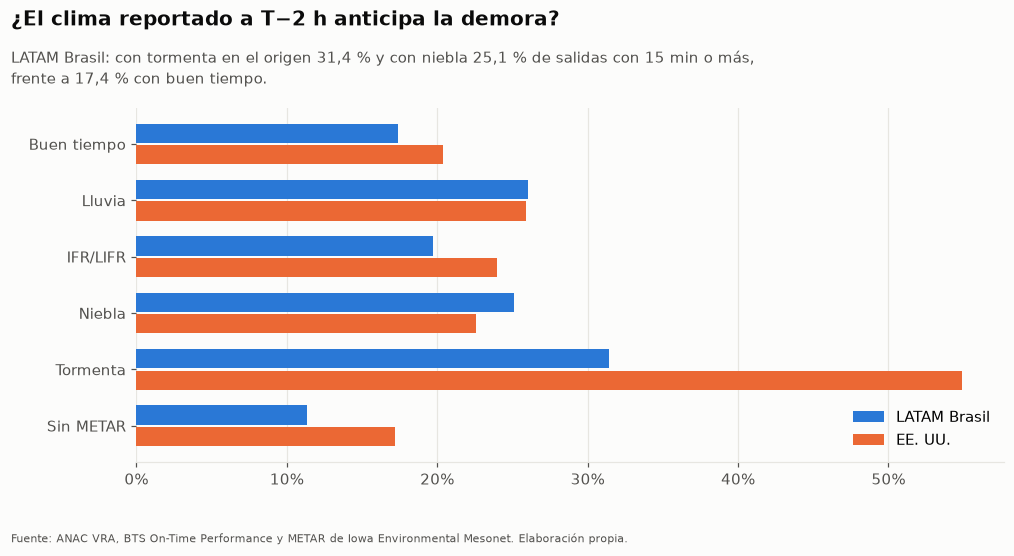

In [9]:
clima = (F.when(F.col("o_fen_tormenta") == 1, "Tormenta").when(F.col("o_fen_niebla") == 1, "Niebla")
         .when(F.col("o_categoria_vuelo").isin("IFR", "LIFR"), "IFR/LIFR")
         .when(F.col("o_fen_lluvia") == 1, "Lluvia").when(F.col("clima_disponible") == 0, "Sin METAR")
         .otherwise("Buen tiempo"))
g5 = tasa_por(gold.where(F.col("segmento") != "Otras Brasil").withColumn("clima", clima), "segmento", "clima")
orden = ["Buen tiempo", "Lluvia", "IFR/LIFR", "Niebla", "Tormenta", "Sin METAR"]
tabla = g5.pivot(index="clima", columns="segmento", values="t15").reindex(orden)
fig, ax = lienzo(9.5, 5.2, izquierda=0.14)
alto = 0.38
for i, (nombre, color) in enumerate([("LATAM Brasil", AZUL), ("EE. UU.", NARANJA)]):
    if nombre in tabla.columns:
        ys = [k + (i - 0.5) * alto for k in range(len(orden))]
        ax.barh(ys, tabla[nombre].fillna(0), height=alto - 0.04, color=color, label=nombre)
ax.set_yticks(range(len(orden)), orden)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
lat = tabla.get("LATAM Brasil", pd.Series(dtype=float))
cerrar(fig, "g5_clima_metar",
       "¿El clima reportado a T−2 h anticipa la demora?",
       f"LATAM Brasil: con tormenta en el origen {pct(lat.get('Tormenta'))} y con niebla {pct(lat.get('Niebla'))} de "
       f"salidas con 15 min o más,\nfrente a {pct(lat.get('Buen tiempo'))} con buen tiempo.",
       "Un protocolo de clima: si el METAR de T−2 h trae tormenta o niebla, pre-asignar recursos y avisar a pasajeros.")

## G6. ¿Cuando la red del aeropuerto ya viene atrasada, el vuelo también se atrasa?

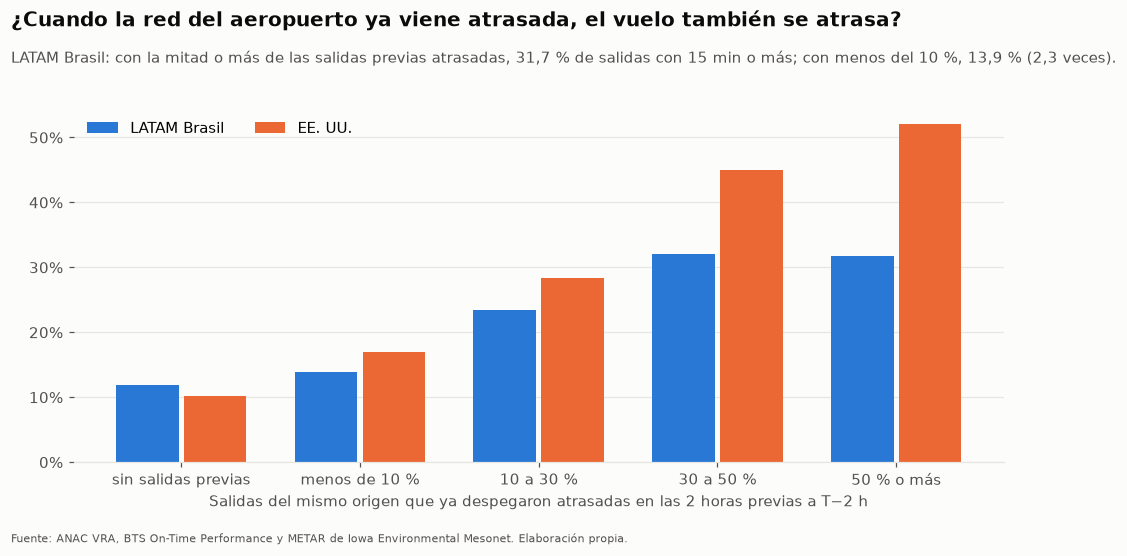

In [10]:
tramo = (F.when(F.col("red_n_salidas") == 0, "0 sin salidas previas")
         .when(F.col("red_frac_atrasadas") < 0.1, "1 menos de 10 %")
         .when(F.col("red_frac_atrasadas") < 0.3, "2 10 a 30 %")
         .when(F.col("red_frac_atrasadas") < 0.5, "3 30 a 50 %").otherwise("4 50 % o más"))
g6 = tasa_por(gold.where(F.col("segmento") != "Otras Brasil").withColumn("tramo", tramo), "segmento", "tramo")
tabla = g6.pivot(index="tramo", columns="segmento", values="t15").sort_index()
fig, ax = lienzo()
ancho = 0.38
for i, (nombre, color) in enumerate([("LATAM Brasil", AZUL), ("EE. UU.", NARANJA)]):
    if nombre in tabla.columns:
        xs = [k + (i - 0.5) * ancho for k in range(len(tabla))]
        ax.bar(xs, tabla[nombre].fillna(0), width=ancho - 0.03, color=color, label=nombre)
ax.set_xticks(range(len(tabla)), [t[2:] for t in tabla.index])
ax.set_xlabel("Salidas del mismo origen que ya despegaron atrasadas en las 2 horas previas a T−2 h")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=2)
lat = tabla.get("LATAM Brasil", pd.Series(dtype=float))
alto_v, bajo_v = lat.get("4 50 % o más"), lat.get("1 menos de 10 %")
veces = f"{alto_v / bajo_v:.1f}".replace(".", ",") if alto_v and bajo_v else "s/d"
cerrar(fig, "g6_propagacion_red",
       "¿Cuando la red del aeropuerto ya viene atrasada, el vuelo también se atrasa?",
       f"LATAM Brasil: con la mitad o más de las salidas previas atrasadas, {pct(alto_v)} de salidas con 15 min o "
       f"más; con menos del 10 %, {pct(bajo_v)} ({veces} veces).",
       "Una alerta de red: si la fracción de salidas atrasadas sube, escalar al coordinador del hub.")

## G7. ¿La demora del mismo vuelo el día anterior predice la de hoy?

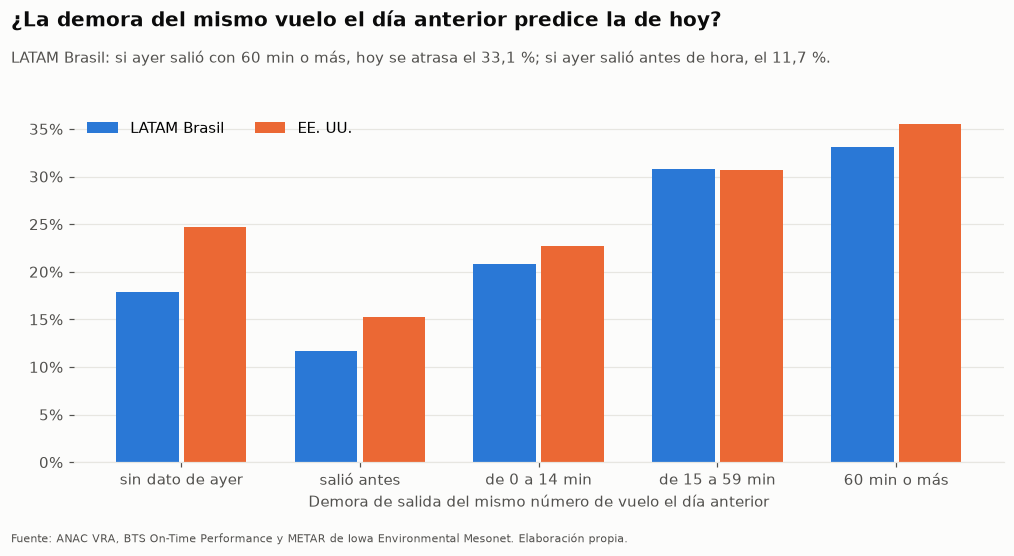

In [11]:
ayer = (F.when(F.col("prev_dia_conocido") == 0, "0 sin dato de ayer")
        .when(F.col("prev_dia_demora") < 0, "1 salió antes")
        .when(F.col("prev_dia_demora") < 15, "2 de 0 a 14 min")
        .when(F.col("prev_dia_demora") < 60, "3 de 15 a 59 min").otherwise("4 60 min o más"))
g7 = tasa_por(gold.where(F.col("segmento") != "Otras Brasil").withColumn("ayer", ayer), "segmento", "ayer")
tabla = g7.pivot(index="ayer", columns="segmento", values="t15").sort_index()
fig, ax = lienzo()
for i, (nombre, color) in enumerate([("LATAM Brasil", AZUL), ("EE. UU.", NARANJA)]):
    if nombre in tabla.columns:
        xs = [k + (i - 0.5) * ancho for k in range(len(tabla))]
        ax.bar(xs, tabla[nombre].fillna(0), width=ancho - 0.03, color=color, label=nombre)
ax.set_xticks(range(len(tabla)), [t[2:] for t in tabla.index])
ax.set_xlabel("Demora de salida del mismo número de vuelo el día anterior")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=2)
lat = tabla.get("LATAM Brasil", pd.Series(dtype=float))
cerrar(fig, "g7_demora_dia_anterior",
       "¿La demora del mismo vuelo el día anterior predice la de hoy?",
       f"LATAM Brasil: si ayer salió con 60 min o más, hoy se atrasa el {pct(lat.get('4 60 min o más'))}; "
       f"si ayer salió antes de hora, el {pct(lat.get('1 salió antes'))}.",
       "Planeamiento de red puede revisar cada mes los números de vuelo con demora repetida.")

## G8. ¿Se parecen los mercados de Brasil y EE. UU.?

Un solo modelo aprende de los dos países. Este gráfico compara sus tasas básicas para entender qué tan distinto es
cada mercado.

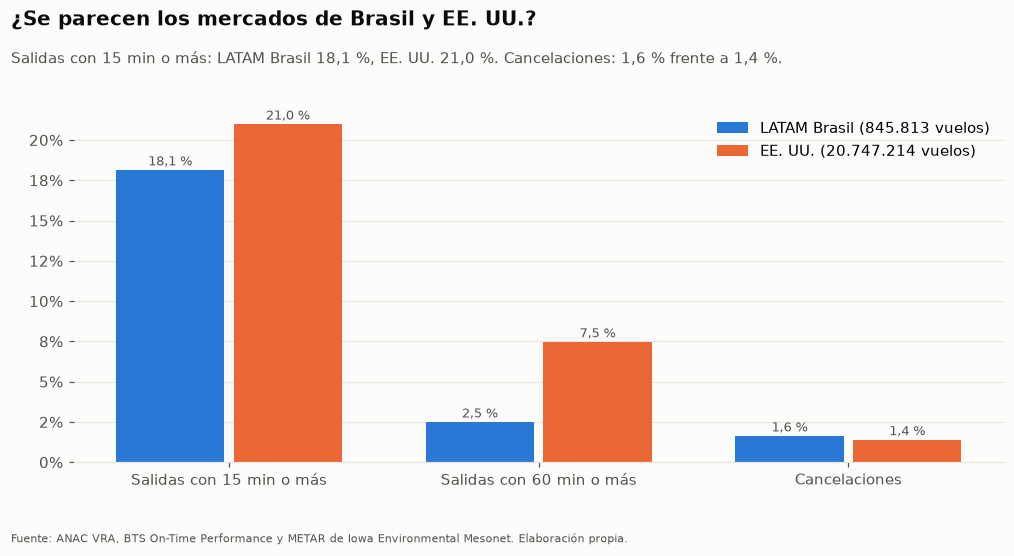

In [12]:
resumen_pais = (
    vuelos.withColumn("segmento", segmento).where(F.col("segmento") != "Otras Brasil")
    .groupBy("segmento").agg(
        F.avg("y_demora15").alias("Salidas con 15 min o más"),
        F.avg("y_demora60").alias("Salidas con 60 min o más"),
        F.avg(F.col("cancelado").cast("int")).alias("Cancelaciones"),
        F.count("*").alias("n"),
    ).toPandas().set_index("segmento")
)
metricas = ["Salidas con 15 min o más", "Salidas con 60 min o más", "Cancelaciones"]
fig, ax = lienzo()
for i, (nombre, color) in enumerate([("LATAM Brasil", AZUL), ("EE. UU.", NARANJA)]):
    if nombre in resumen_pais.index:
        xs = [k + (i - 0.5) * ancho for k in range(len(metricas))]
        valores = resumen_pais.loc[nombre, metricas]
        ax.bar(xs, valores, width=ancho - 0.03, color=color, label=f"{nombre} ({miles(resumen_pais.loc[nombre, 'n'])} vuelos)")
        for x, v in zip(xs, valores):
            ax.text(x, v + 0.003, pct(v), ha="center", fontsize=8.5, color=TINTA2)
ax.set_xticks(range(len(metricas)), metricas)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
br_ = resumen_pais.reindex(["LATAM Brasil"]).iloc[0]
us_ = resumen_pais.reindex(["EE. UU."]).iloc[0]
cerrar(fig, "g8_brasil_vs_eeuu",
       "¿Se parecen los mercados de Brasil y EE. UU.?",
       f"Salidas con 15 min o más: LATAM Brasil {pct(br_['Salidas con 15 min o más'])}, EE. UU. "
       f"{pct(us_['Salidas con 15 min o más'])}. Cancelaciones: {pct(br_['Cancelaciones'])} frente a "
       f"{pct(us_['Cancelaciones'])}.",
       "EE. UU. aporta volumen para aprender patrones generales (hora, clima, red); la evaluación se reporta por país.")

## Resumen de hallazgos

In [13]:
tabla = pd.DataFrame(hallazgos)[["pregunta", "hallazgo", "implicancia", "figura"]]
tabla.to_csv(EVID / "hallazgos_eda.csv", index=False)
pd.set_option("display.max_colwidth", 200)
tabla

,pregunta,hallazgo,implicancia,figura
0,¿Cuál es la línea base de LATAM en Brasil y cómo evoluciona?,"2025: 19,0 % de las salidas con 15 min o más y 2,5 % con 60 min o más (298.582 salidas operadas). Peor mes: 12/2025 con 31,9 %.",Es la línea base contra la que se medirá el efecto de la alerta temprana.,g1_linea_base_latam.png
1,¿LATAM sale más o menos puntual que Azul y Gol?,"2025, salidas con 15 min o más: LATAM 19,0 %, Azul 14,7 %, Gol 13,7 %.",Ubica a LATAM frente a su competencia directa en el mismo mercado y con la misma fuente.,g2_latam_vs_competencia.png
2,¿Qué aeropuertos concentran las salidas demoradas de LATAM?,"Guarulhos (SBGR): 26,4 % de salidas con 15 min o más (red: 18,1 %) y el 34,9 % de todas las salidas demoradas de LATAM. Los 12 orígenes con más salidas.",Priorizar el turno del CCO en los hubs con más volumen y más demora.,g3_aeropuertos.png
3,¿En qué hora del día se concentra el riesgo?,"LATAM Brasil: 25,0 % de salidas con 15 min o más entre las 18 y las 23 h, frente a 12,9 % entre las 6 y las 11 h. En los dos mercados la demora se acumula a lo largo del día.",Reforzar la holgura y la vigilancia del CCO en el turno de tarde y noche.,g4_hora_del_dia.png
4,¿El clima reportado a T−2 h anticipa la demora?,"LATAM Brasil: con tormenta en el origen 31,4 % y con niebla 25,1 % de salidas con 15 min o más, frente a 17,4 % con buen tiempo.","Un protocolo de clima: si el METAR de T−2 h trae tormenta o niebla, pre-asignar recursos y avisar a pasajeros.",g5_clima_metar.png
5,"¿Cuando la red del aeropuerto ya viene atrasada, el vuelo también se atrasa?","LATAM Brasil: con la mitad o más de las salidas previas atrasadas, 31,7 % de salidas con 15 min o más; con menos del 10 %, 13,9 % (2,3 veces).","Una alerta de red: si la fracción de salidas atrasadas sube, escalar al coordinador del hub.",g6_propagacion_red.png
6,¿La demora del mismo vuelo el día anterior predice la de hoy?,"LATAM Brasil: si ayer salió con 60 min o más, hoy se atrasa el 33,1 %; si ayer salió antes de hora, el 11,7 %.",Planeamiento de red puede revisar cada mes los números de vuelo con demora repetida.,g7_demora_dia_anterior.png
7,¿Se parecen los mercados de Brasil y EE. UU.?,"Salidas con 15 min o más: LATAM Brasil 18,1 %, EE. UU. 21,0 %. Cancelaciones: 1,6 % frente a 1,4 %.","EE. UU. aporta volumen para aprender patrones generales (hora, clima, red); la evaluación se reporta por país.",g8_brasil_vs_eeuu.png


In [14]:
spark.stop()